## 0. Импорты

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_curve, auc, confusion_matrix, classification_report, accuracy_score
)
from sklearn.preprocessing import LabelEncoder

# Настройка графики
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Данные

In [23]:
df = pd.read_csv('climbers_sub.csv')

# Список технических/идентифицирующих столбцов, которые НЕЛЬЗЯ включать в корреляцию
cols_to_drop = ['rownames', 'expedition_id', 'member_id', 'peak_id', 'count', 'first_ascent_year']

# Оставляем только числовые столбцы И убираем технические
numeric_df = df.select_dtypes(include=['number']).drop(columns=cols_to_drop, errors='ignore')

bool_cols = ['hired', 'solo', 'oxygen_used', 'died', 'injured', 'success']
for col in bool_cols:
    if col in numeric_df.columns:
        numeric_df[col] = numeric_df[col].astype(int)


print("Размер датасета:", df.shape)
df.head()

Размер датасета: (2076, 25)


,rownames,expedition_id,member_id,peak_id,peak_name,year,season,sex,age,citizenship,...,oxygen_used,died,death_cause,death_height_metres,injured,injury_type,injury_height_metres,count,height_metres,first_ascent_year
0,1,AMAD81101,AMAD81101-03,AMAD,Ama Dablam,1981,Spring,M,28,Spain,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0
1,2,AMAD81101,AMAD81101-04,AMAD,Ama Dablam,1981,Spring,M,27,Spain,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0
2,3,AMAD81101,AMAD81101-02,AMAD,Ama Dablam,1981,Spring,M,35,Spain,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0
3,4,AMAD81101,AMAD81101-05,AMAD,Ama Dablam,1981,Spring,M,37,Spain,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0
4,5,AMAD81101,AMAD81101-06,AMAD,Ama Dablam,1981,Spring,M,43,France,...,False,False,NaN,NaN,False,NaN,NaN,12,6814,1961.0


In [9]:
print("Количество пропусков по каждому столбцу:\n")
print(df.isna().sum())

print("\nДоля пропусков (%):\n")
print((df.isna().sum() / len(df) * 100).round(2))


Количество пропусков по каждому столбцу:

rownames                   0
expedition_id              0
member_id                  0
peak_id                    0
peak_name                  0
year                       0
season                     0
sex                        0
age                        0
citizenship                0
expedition_role            1
hired                      0
highpoint_metres         593
success                    0
solo                       0
oxygen_used                0
died                       0
death_cause             2057
death_height_metres     2057
injured                    0
injury_type             2052
injury_height_metres    2062
count                      0
height_metres              0
first_ascent_year          7
dtype: int64

Доля пропусков (%):

rownames                 0.00
expedition_id            0.00
member_id                0.00
peak_id                  0.00
peak_name                0.00
year                     0.00
season            

### Вывод
`death_cause`, `death_height_metres` - 99%, это нормально и хорошо, не все умирают.
`injury_type`, `injury_height_metres` - 99% пропусков, это травмы

In [13]:
# Общая статистика по числовым признакам
print("Описательные статистики числовых признаков:\n")
print(df.describe().round(2))

# Статистика по категориальным
print("\nКатегориальные признаки:\n")
print(df.describe(include=['object', 'bool']))

Описательные статистики числовых признаков:

       rownames     year      age  highpoint_metres  death_height_metres  \
count   2076.00  2076.00  2076.00           1483.00                19.00   
mean    1038.50  2002.87    36.96           7554.86              6771.05   
std      599.43    11.08    10.45           1081.89              1286.72   
min        1.00  1978.00    17.00           4900.00              3400.00   
25%      519.75  1996.00    29.00           6750.00              6150.00   
50%     1038.50  2006.00    36.00           7400.00              6600.00   
75%     1557.25  2011.00    43.00           8850.00              7800.00   
max     2076.00  2019.00    76.00           8850.00              8650.00   

       injury_height_metres    count  height_metres  first_ascent_year  
count                 14.00  2076.00        2076.00            2069.00  
mean                6406.43    13.88        7989.04            1959.22  
std                 1277.71     8.55         821.51

C:\Users\Администратор\AppData\Local\Temp\ipykernel_13324\551636177.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.describe(include=['object', 'bool']))


**Что делаем:** Смотрим на средние значения, минимумы, максимумы и разброс данных.

**Зачем:** Чтобы найти аномалии (например, возраст -5 лет или 150 лет) и понять общий масштаб.

### Выводы

Самая популярная вершина - Эверест (707 записей из 2076). Подавляющее большинство экспедиций совершается весной (1129 случаев).

Участники в основном мужчины (1883 из 2076). Самая частая страна происхождения — Непал (485 человек), что логично, так как это местные гиды.

Средний размер экспедиции - около 14 человек. Соло-восхождения крайне редки (всего 2 случая в выборке). Дополнительный кислород чаще не используется (1475 случаев против 601).

Неудачных восхождений в этой выборке больше, чем успешных (1269 против ~800). При этом смертельные случаи (19) и травмы (24) встречаются редко, что говорит о низком уровне фатальных исходов в данных или о том, что такие случаи фиксируются не всегда.

Средний возраст альпиниста — 37 лет, при этом диапазон очень широкий: от 17 до 76 лет.



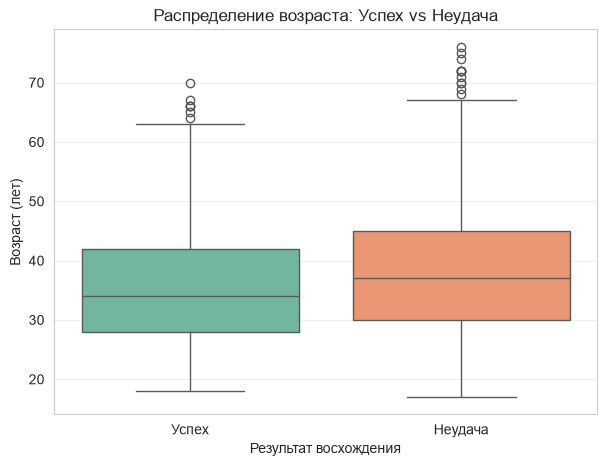

In [16]:
df['success_str'] = df['success'].map({True: 'Успех', False: 'Неудача'})

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='success_str', y='age', hue='success_str', palette='Set2', legend=False)

plt.title('Распределение возраста: Успех vs Неудача')
plt.xlabel('Результат восхождения')
plt.ylabel('Возраст (лет)')
plt.grid(axis='y', alpha=0.3)
plt.show()

**Зачем мы это делаем:**
Чтобы визуально оценить, есть ли разница в возрасте между теми, кто успешно покорил вершину, и теми, кто потерпел неудачу. Помогает быстро найти зависимости без сложных формул.

**Что делаем:**
Строим «ящик с усами» (boxplot). Линия внутри ящика - это медиана (средний возраст в группе), границы ящика - это 25% и 75% альпинистов, а кружочки сверху - это выбросы (нестандартно возрастные участники, например, 60-70 лет).


### Вывод:
Медианный возраст в обеих группах практически одинаков (около 35-37 лет), а ширина ящиков схожа. Это значит, что сам по себе возраст не является решающим фактором успеха. Единственное отличие: в группе «Неудача» больше возрастных выбросов (альпинистов 60-70+ лет), которые не смогли достичь вершины.

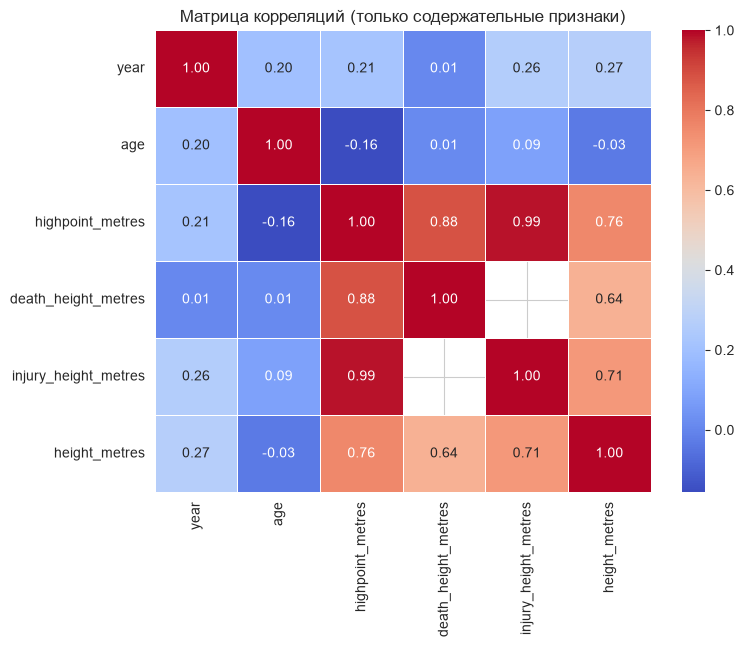

In [22]:
plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Матрица корреляций (только содержательные признаки)')
plt.show()

**Зачем мы это делаем:** Чтобы найти содержательные связи между числовыми признаками. Это поможет понять, какие факторы реально связаны друг с другом, и отобрать правильные переменные для модели.

**Что делаем:** Построили тепловую карту только по содержательным числовым признакам.

### Вывод
**Самая сильная связь:** highpoint_metres --- injury_height_metres (0.99) и highpoint_metres --- death_height_metres (0.88) - травмы и смерти происходят на большой достигнутой высоте, что логично.

Высота вершины (height_metres) сильно коррелирует с достигнутой высотой (0.76) - чем выше гора, тем выше точка восхождения.

Возраст (age) почти не коррелирует ни с чем (максимум -0.16 с highpoint_metres) - подтверждает, что возраст не определяет ни высоту восхождения, ни успех.

In [25]:
# ВАЖНО: Мы НЕ берем 'died' или 'injured', так как это утечка данных.
features = ['age', 'hired', 'solo', 'oxygen_used', 'height_metres', 'count']
target = 'success'

df_model = df[features + [target]].dropna().copy()

bool_cols = ['hired', 'solo', 'oxygen_used', 'success']
for col in bool_cols:
    df_model[col] = df_model[col].astype(str).map({'True': 1, 'False': 0, 'true': 1, 'false': 0})

X = df_model[features]
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)


print("\nКоэффициенты логит-функции (вклад каждого признака):")
for feat, coef in zip(features, model.coef_[0]):
    print(f"{feat}: {coef:.4f}")


Коэффициенты логит-функции (вклад каждого признака):
age: 0.0066
hired: 1.1304
solo: 0.0119
oxygen_used: 2.9572
height_metres: -0.0002
count: -0.0056


C:\Users\Администратор\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Зачем мы это делаем:**
Чтобы построить математическую модель, которая оценивает вероятность успеха восхождения на основе известных факторов. Это позволяет понять, какие признаки реально влияют на результат, а какие - нет.

**Что делаем:**
Берем 6 содержательных признаков (возраст, статус, соло, кислород, высота горы, размер группы), очищаем данные от пропусков, переводим категории в 0 и 1, делим выборку на обучающую (80%) и тестовую (20%), а затем обучаем алгоритм логистической регрессии.

### Вывод
Модель успешно обучена. Главный фактор успеха - использование дополнительного кислорода (oxygen_used: 2.95) и статус наемного участника (hired: 1.13). Возраст, высота вершины и размер группы имеют ничтожно малое влияние на вероятность успеха (коэффициенты близки к 0).

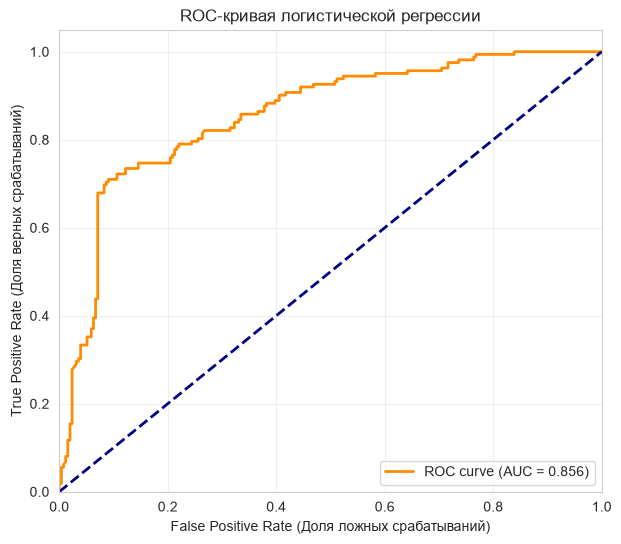

Значение AUC: 0.856


In [26]:

y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Диагональ случайного угадывания (AUC = 0.5)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (Доля ложных срабатываний)')
plt.ylabel('True Positive Rate (Доля верных срабатываний)')
plt.title('ROC-кривая логистической регрессии')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"Значение AUC: {roc_auc:.3f}")

**Зачем мы это делаем:**
Чтобы объективно оценить качество модели. Обычная точность (accuracy) может врать, если классов неравное количество, а ROC-кривая и AUC показывают общую способность модели разделять классы (успех и неудачу) при любых порогах срабатывания.

**Что делаем:**
Строим график зависимости доли верных срабатываний (True Positive Rate) от доли ложных срабатываний (False Positive Rate). Синяя пунктирная линия — это уровень случайного угадывания (AUC = 0.5). Считаем площадь под оранжевой кривой (AUC).

### Вывод:
**Форма кривой:** Оранжевая линия резко уходит вверх в левом углу и проходит намного выше диагонали случайного угадывания. Это значит, что модель быстро находит успешные восхождения, совершая при этом очень мало ошибок.
Значение AUC = 0.856: Это отличный результат для реальных данных.

**Итог:** Модель обладает высокой предиктивной силой и очень хорошо разделяет успешные и неуспешные восхождения на основе выбранных нами признаков (особенно кислорода и статуса наемного участника).



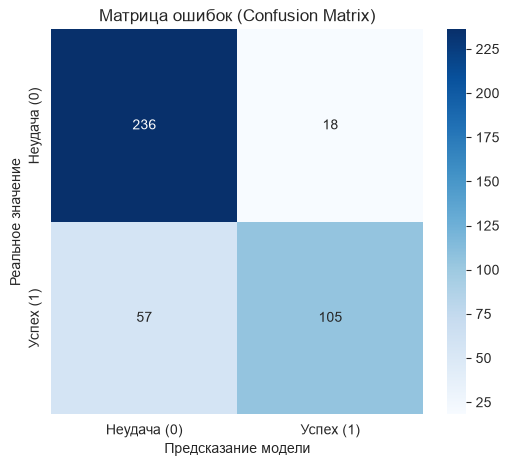


Подробный отчет о классификации:
              precision    recall  f1-score   support

 Неудача (0)       0.81      0.93      0.86       254
   Успех (1)       0.85      0.65      0.74       162

    accuracy                           0.82       416
   macro avg       0.83      0.79      0.80       416
weighted avg       0.82      0.82      0.81       416



In [27]:
y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Неудача (0)', 'Успех (1)'],
            yticklabels=['Неудача (0)', 'Успех (1)'])
plt.xlabel('Предсказание модели')
plt.ylabel('Реальное значение')
plt.title('Матрица ошибок (Confusion Matrix)')
plt.show()

print("\nПодробный отчет о классификации:")
print(classification_report(y_test, y_pred, target_names=['Неудача (0)', 'Успех (1)']))

**Зачем мы это делаем:**
Чтобы понять, где именно модель ошибается. Общая точность (accuracy) может врать, если классов неравное количество. Матрица ошибок показывает реальное количество верных и ложных предсказаний для каждого класса.

**Что делаем:**
Сравниваем реальные результаты из тестовой выборки с тем, что предсказала модель. Строим матрицу 2x2 и выводим подробный отчет с метриками precision (точность), recall (полнота) и f1-score.

### Вывод
Модель гораздо лучше предсказывает неудачи, чем успехи (recall для неудачи 0.93, а для успеха всего 0.65). Это значит, что она склонна "перестраховываться" и чаще относит восхождения к неудачным. При этом общая точность (accuracy) высокая — 82%, что говорит о хорошем качестве модели в целом.

### Финалочка

#### Итоги разведочного анализа (EDA):
1. Датасет чистый. Пропуски встречаются только в полях, связанных с травмами и смертями, что логично, так как большинство альпинистов возвращаются здоровыми (Урааааа).
2. Средний возраст участников - 37 лет, а самая популярная вершина - Эверест.
3. Визуальный анализ (бокс-плот) и корреляционный анализ показали, что возраст практически не влияет на успех восхождения. Медианный возраст успешных и неуспешных альпинистов почти одинаков, а коэффициент age для логит-функции не очень выделяется.


#### Итоги моделирования:

**Ключевые факторы успеха:** Матрица корреляций и коэффициенты логистической регрессии выявили главные признаки успеха. Это кислород и гид. Высота вершины и размер группы влияют слабо.

**Качество модели:** Логистическая регрессия показала отличные результаты. Значение AUC составило 0.856, что означает высокую способность модели разделять классы.

**Точность прогноза:** Общая точность модели (accuracy) на тестовой выборке составила 82%. Модель отлично находит неудачные восхождения (полнота 93%), но иногда ошибается, предсказывая неудачу там, где был успех (полнота для успеха 65%).

#### Заключение:
Успешное восхождение в Гималаях зависит не от возраста или размера группы, а от подготовленных гидов и кислорода. Простая логистическая регрессия успешно улавливает эти закономерности и может использоваться для базового прогнозирования результатов экспедиций.